### Cell 1: Imports
Import all libraries needed for data loading, the model, training, and visualization.

In [85]:
import os
import re
import glob
import random
import time
import json
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import timm
from tqdm.notebook import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Imports done.")
print("Torch version:", torch.__version__)
print("Timm version:", timm.__version__)


Imports done.
Torch version: 2.5.1+cu121
Timm version: 1.0.28


### Cell 2: Device configuration
Set the device, and define global settings (IMAGE_SIZE, BATCH_SIZE, class names, embedding dim). Change IMAGE_SIZE here to switch resolution everywhere else in the notebook.

In [86]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 320
BATCH_SIZE = 16
NUM_CLASSES = 10

CLASS_NAMES = [
    "Cheops",
    "LisaPathfinder",
    "ObservationSat1",
    "Proba2",
    "Proba3",
    "Proba3ocs",
    "Smart1",
    "Soho",
    "VenusExpress",
    "XMM Newton",
]

EMBEDDING_DIM = 16
FUSED_CHANNELS = 64
FEATURE_SIZE = 96  # spatial size of the fused feature map

print("Device:", device)
print("IMAGE_SIZE:", IMAGE_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)


Device: cuda
IMAGE_SIZE: 320
BATCH_SIZE: 16


### Cell 3: Dataset path
Point to the already-downloaded local dataset folders. Nothing is re-downloaded.

In [87]:
DATA_ROOT = "/content/spark2026_data/stream-1-train-val"
IMAGES_DIR = os.path.join(DATA_ROOT, "images")
MASKS_DIR = os.path.join(DATA_ROOT, "mask")

assert os.path.isdir(IMAGES_DIR), f"Images folder not found: {IMAGES_DIR}"
assert os.path.isdir(MASKS_DIR), f"Masks folder not found: {MASKS_DIR}"

print("Images dir:", IMAGES_DIR)
print("Masks dir:", MASKS_DIR)


Images dir: /content/spark2026_data/stream-1-train-val/images
Masks dir: /content/spark2026_data/stream-1-train-val/mask


### Cell 4: Find image files
Walk through each class folder and collect all `*_img.jpg` files, skipping Mac metadata files that start with `._`.

In [88]:
def is_valid_file(path):
    # Ignore Mac metadata files such as ._image_00001_img.jpg
    return not os.path.basename(path).startswith("._")


all_image_paths = []

for class_name in CLASS_NAMES:

    class_folder = os.path.join(
        IMAGES_DIR,
        class_name
    )

    if not os.path.isdir(class_folder):
        print(
            "Warning: missing class folder:",
            class_folder
        )
        continue

    found = glob.glob(
        os.path.join(
            class_folder,
            "**",
            "*_img.jpg"
        ),
        recursive=True
    )

    found = [
        f for f in found
        if is_valid_file(f)
    ]

    all_image_paths.extend(found)


print(
    "Total raw image files found:",
    len(all_image_paths)
)

Total raw image files found: 80000


### Cell 5: Find matching masks
For every image, build the expected mask path (`_img.jpg` -> `_layer.jpg` in the matching class folder under `mask/`) and keep only pairs where both files exist.

In [89]:
def image_path_to_mask_path(img_path):

    # Get:
    # .../images/Cheops/train/image_01096_img.jpg

    split_name = os.path.basename(
        os.path.dirname(img_path)
    )

    class_name = os.path.basename(
        os.path.dirname(
            os.path.dirname(img_path)
        )
    )

    filename = os.path.basename(
        img_path
    )

    mask_filename = filename.replace(
        "_img.jpg",
        "_layer.jpg"
    )

    return os.path.join(
        MASKS_DIR,
        class_name,
        split_name,
        mask_filename
    )


paired_images = []
paired_masks = []
paired_labels = []

for img_path in all_image_paths:

    mask_path = image_path_to_mask_path(
        img_path
    )

    if (
        is_valid_file(mask_path)
        and os.path.isfile(mask_path)
    ):

        class_name = os.path.basename(
            os.path.dirname(
                os.path.dirname(img_path)
            )
        )

        paired_images.append(
            img_path
        )

        paired_masks.append(
            mask_path
        )

        paired_labels.append(
            CLASS_NAMES.index(
                class_name
            )
        )


print(
    "Total valid image-mask pairs:",
    len(paired_images)
)

Total valid image-mask pairs: 80000


### Cell 6: Remove invalid ._ Mac files
A final safety pass that removes any remaining Mac metadata files and any pair where a file is missing on disk.

In [90]:
def clean_pairs(images, masks, labels):
    clean_images, clean_masks, clean_labels = [], [], []
    for img_p, mask_p, lbl in zip(images, masks, labels):
        img_name = os.path.basename(img_p)
        mask_name = os.path.basename(mask_p)
        if img_name.startswith("._") or mask_name.startswith("._"):
            continue
        if not os.path.isfile(img_p) or not os.path.isfile(mask_p):
            continue
        clean_images.append(img_p)
        clean_masks.append(mask_p)
        clean_labels.append(lbl)
    return clean_images, clean_masks, clean_labels

paired_images, paired_masks, paired_labels = clean_pairs(paired_images, paired_masks, paired_labels)

print("Total pairs after cleaning:", len(paired_images))


Total pairs after cleaning: 80000


### Cell 7: Create train/validation/test split
Split into 80% train, 10% validation, 10% test, stratified by class so every class is represented in each split.

In [91]:
train_imgs, temp_imgs, train_masks, temp_masks, train_labels, temp_labels = train_test_split(
    paired_images, paired_masks, paired_labels,
    test_size=0.20, random_state=SEED, stratify=paired_labels
)

val_imgs, test_imgs, val_masks, test_masks, val_labels, test_labels = train_test_split(
    temp_imgs, temp_masks, temp_labels,
    test_size=0.50, random_state=SEED, stratify=temp_labels
)

print("Train pairs:", len(train_imgs))
print("Val pairs:", len(val_imgs))
print("Test pairs:", len(test_imgs))


Train pairs: 64000
Val pairs: 8000
Test pairs: 8000


### Cell 8: Dataset class
Loads an image and its mask, resizes both to IMAGE_SIZE, normalizes the image with ImageNet mean/std, and binarizes the mask (0 = background, 1 = object).

In [92]:
class SparkSegDataset(Dataset):
    def __init__(self, image_paths, mask_paths, labels, image_size=IMAGE_SIZE):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.labels = labels
        self.image_size = image_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]
        label = self.labels[idx]

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 0).astype(np.float32)

        image = image.astype(np.float32) / 255.0
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        image = (image - mean) / std
        image = np.transpose(image, (2, 0, 1))

        image_tensor = torch.from_numpy(image).float()
        mask_tensor = torch.from_numpy(mask).float()
        label_tensor = torch.tensor(label, dtype=torch.long)

        return image_tensor, mask_tensor, label_tensor

print("SparkSegDataset class defined.")


SparkSegDataset class defined.


### Cell 9: DataLoaders
Build the three datasets and DataLoaders. `num_workers=0` is used because multiprocessing workers previously crashed in this notebook.

In [93]:
# ============================================================
# Cell 9: DataLoaders
# Stable configuration for current Jupyter/container
# ============================================================

BATCH_SIZE = 16

# ------------------------------------------------------------
# Datasets
# ------------------------------------------------------------

train_dataset = SparkSegDataset(
    train_imgs,
    train_masks,
    train_labels,
    image_size=IMAGE_SIZE
)

val_dataset = SparkSegDataset(
    val_imgs,
    val_masks,
    val_labels,
    image_size=IMAGE_SIZE
)

test_dataset = SparkSegDataset(
    test_imgs,
    test_masks,
    test_labels,
    image_size=IMAGE_SIZE
)

# ------------------------------------------------------------
# Pin CPU memory for faster CPU -> GPU transfer
# ------------------------------------------------------------

pin_mem = torch.cuda.is_available()

# ------------------------------------------------------------
# DataLoaders
#
# num_workers=0 is intentional:
# your container is throwing shared-memory bus errors
# with multiprocessing workers.
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_mem
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_mem
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_mem
)

# ------------------------------------------------------------
# Information
# ------------------------------------------------------------

print("DataLoaders created.")
print()
print("Batch size    :", BATCH_SIZE)
print("Workers       : 0")
print("Pin memory    :", pin_mem)
print()
print("Train batches :", len(train_loader))
print("Val batches   :", len(val_loader))
print("Test batches  :", len(test_loader))

DataLoaders created.

Batch size    : 16
Workers       : 0
Pin memory    : True

Train batches : 4000
Val batches   : 500
Test batches  : 500


### Cell 10: Check one batch
Pull one batch and print shapes to confirm the pipeline is correct before building the model.

In [94]:
import cv2

print("cv2 location:")
print(cv2.__file__)

print("\nHas imread:")
print(hasattr(cv2, "imread"))

print("\ncv2 version:")
print(getattr(cv2, "__version__", "Unknown"))

cv2 location:
/usr/local/lib/python3.12/dist-packages/cv2/__init__.py

Has imread:
True

cv2 version:
4.10.0


In [95]:
batch = next(iter(train_loader))
images, masks, labels = batch

print("Images shape:", images.shape)   # [B,3,IMAGE_SIZE,IMAGE_SIZE]
print("Masks shape:", masks.shape)     # [B,IMAGE_SIZE,IMAGE_SIZE]
print("Labels shape:", labels.shape)   # [B]
print("Mask unique values:", torch.unique(masks))


Images shape: torch.Size([16, 3, 320, 320])
Masks shape: torch.Size([16, 320, 320])
Labels shape: torch.Size([16])
Mask unique values: tensor([0., 1.])


### Cell 11: RepViT backbone
Wrap `timm`'s `repvit_m0_9` in `features_only` mode. Falls back to random weights if pretrained weights cannot be downloaded.

In [96]:
foreground_batches = 0
total_checked = 20

for i, batch in enumerate(train_loader):

    images, masks, labels = batch

    if torch.any(masks > 0):
        foreground_batches += 1

    if i + 1 >= total_checked:
        break

print(
    f"Batches with foreground: "
    f"{foreground_batches}/{total_checked}"
)

Batches with foreground: 20/20


In [97]:
class RepViTBackbone(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        try:
            self.backbone = timm.create_model(
                "repvit_m0_9",
                pretrained=pretrained,
                features_only=True
            )
        except Exception as e:
            print("Pretrained weights not available, loading without pretrained weights.")
            print("Reason:", e)
            self.backbone = timm.create_model(
                "repvit_m0_9",
                pretrained=False,
                features_only=True
            )
        self.feature_info = self.backbone.feature_info

    def forward(self, x):
        # Returns a list of feature maps at different resolutions
        return self.backbone(x)

backbone = RepViTBackbone(pretrained=True).to(device)
print("RepViT backbone created.")


RepViT backbone created.


### Cell 12: Inspect backbone features
Run one dummy forward pass and print the shape of every feature level. We select index 0 (high-resolution, ~96x96) and index 2 (deep, ~24x24) only, per the required architecture.

In [98]:
backbone.eval()
with torch.no_grad():
    dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
    dummy_features = backbone(dummy_input)

for i, feat in enumerate(dummy_features):
    print(f"Feature {i}: shape = {tuple(feat.shape)}")

# We use only two feature levels:
# index 0: high resolution (approximately 96x96), fewer channels
# index 2: deeper resolution (approximately 24x24), more channels
HIGH_RES_INDEX = 0
LOW_RES_INDEX = 2

HIGH_RES_CHANNELS = dummy_features[HIGH_RES_INDEX].shape[1]
LOW_RES_CHANNELS = dummy_features[LOW_RES_INDEX].shape[1]

print("High-res feature channels:", HIGH_RES_CHANNELS, "shape:", dummy_features[HIGH_RES_INDEX].shape)
print("Low-res feature channels:", LOW_RES_CHANNELS, "shape:", dummy_features[LOW_RES_INDEX].shape)

backbone.train()


Feature 0: shape = (1, 48, 80, 80)
Feature 1: shape = (1, 96, 40, 40)
Feature 2: shape = (1, 192, 20, 20)
Feature 3: shape = (1, 384, 10, 10)
High-res feature channels: 48 shape: torch.Size([1, 48, 80, 80])
Low-res feature channels: 192 shape: torch.Size([1, 192, 20, 20])


RepViTBackbone(
  (backbone): FeatureListNet(
    (stem): RepVitStem(
      (conv1): ConvNorm(
        (c): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (act1): GELU(approximate='none')
      (conv2): ConvNorm(
        (c): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (stages_0): RepVitStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): RepViTBlock(
          (token_mixer): RepVggDw(
            (conv): ConvNorm(
              (c): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
              (bn): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
            (conv1): Conv2d(48, 48, kernel_size=(

### Cell 13: Lightweight projection
A simple 1x1 conv + BatchNorm + ReLU block that projects any number of input channels down to FUSED_CHANNELS (64).

In [99]:
class ChannelProjector(nn.Module):
    # Projects any number of input channels to a small fixed number of channels
    def __init__(self, in_channels, out_channels=FUSED_CHANNELS):
        super().__init__()
        self.project = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.project(x)

print("ChannelProjector class defined.")


ChannelProjector class defined.


### Cell 14: Light GELAN
A lightweight GELAN-like fusion block built only from depthwise separable convolutions and 1x1 pointwise convolutions, with a residual connection.

In [100]:
class DepthwiseSeparableConv(nn.Module):
    # Basic depthwise separable convolution block, reused across the model
    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1, stride=1):
        super().__init__()
        padding = dilation * (kernel_size - 1) // 2
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size=kernel_size,
            stride=stride, padding=padding, dilation=dilation,
            groups=in_channels, bias=False
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn(x)
        x = self.act(x)
        return x


class LightGELAN(nn.Module):
    # Very lightweight GELAN-like fusion block for two feature maps of the same size
    def __init__(self, channels=FUSED_CHANNELS):
        super().__init__()
        self.dw_conv1 = DepthwiseSeparableConv(channels * 2, channels)
        self.dw_conv2 = DepthwiseSeparableConv(channels, channels)

    def forward(self, feat_high, feat_low_upsampled):
        x = torch.cat([feat_high, feat_low_upsampled], dim=1)
        x = self.dw_conv1(x)
        residual = x
        x = self.dw_conv2(x)
        x = x + residual
        return x

print("LightGELAN class defined.")


LightGELAN class defined.


### Cell 15: Feature fusion
Projects the two selected backbone features to FUSED_CHANNELS, upsamples the deep feature to match the high-resolution feature, then fuses them with LightGELAN into `[B, 64, 96, 96]`.

In [101]:
class FeatureFusionModule(nn.Module):
    def __init__(self, high_res_channels, low_res_channels, out_channels=FUSED_CHANNELS):
        super().__init__()
        self.project_high = ChannelProjector(high_res_channels, out_channels)
        self.project_low = ChannelProjector(low_res_channels, out_channels)
        self.gelan = LightGELAN(out_channels)

    def forward(self, feat_high, feat_low):
        feat_high = self.project_high(feat_high)
        feat_low = self.project_low(feat_low)
        feat_low_up = F.interpolate(
            feat_low, size=feat_high.shape[2:], mode="bilinear", align_corners=False
        )
        fused = self.gelan(feat_high, feat_low_up)
        return fused

print("FeatureFusionModule class defined.")


FeatureFusionModule class defined.


### Cell 16: Lite-ASPP
A lightweight ASPP with one 1x1 branch, one depthwise 3x3 branch, and one dilated depthwise 3x3 branch, fused back to 64 channels.

In [102]:
class LiteASPP(nn.Module):
    def __init__(self, channels=FUSED_CHANNELS):
        super().__init__()
        self.branch1 = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
        self.branch2 = DepthwiseSeparableConv(channels, channels, kernel_size=3, dilation=1)
        self.branch3 = DepthwiseSeparableConv(channels, channels, kernel_size=3, dilation=2)

        self.fuse = nn.Sequential(
            nn.Conv2d(channels * 3, channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        out = torch.cat([b1, b2, b3], dim=1)
        out = self.fuse(out)
        return out

print("LiteASPP class defined.")


LiteASPP class defined.


### Cell 17: Depthwise decoder
Upsamples from the 96x96 fused feature to the final IMAGE_SIZE in two bilinear + depthwise-conv stages. No large transposed convolutions are used, and the target size is computed dynamically so it works for any IMAGE_SIZE.

In [103]:
class DepthwiseDecoder(nn.Module):
    def __init__(self, in_channels=FUSED_CHANNELS, mid_channels=32):
        super().__init__()
        self.stage1 = DepthwiseSeparableConv(in_channels, mid_channels)
        self.stage2 = DepthwiseSeparableConv(mid_channels, mid_channels)

    def forward(self, x, out_size):
        mid_size = max(out_size // 2, x.shape[2])
        x = F.interpolate(x, size=(mid_size, mid_size), mode="bilinear", align_corners=False)
        x = self.stage1(x)
        x = F.interpolate(x, size=(out_size, out_size), mode="bilinear", align_corners=False)
        x = self.stage2(x)
        return x

print("DepthwiseDecoder class defined.")


DepthwiseDecoder class defined.


### Cell 18: Segmentation head
A small head producing raw logits at `[B, 1, IMAGE_SIZE, IMAGE_SIZE]`. Sigmoid is NOT applied here; it is applied inside the loss functions.

In [104]:
class SegmentationHead(nn.Module):
    def __init__(self, in_channels=32):
        super().__init__()
        self.conv = DepthwiseSeparableConv(in_channels, in_channels)
        self.out_conv = nn.Conv2d(in_channels, 1, kernel_size=1)

    def forward(self, x):
        x = self.conv(x)
        x = self.out_conv(x)
        return x

print("SegmentationHead class defined.")


SegmentationHead class defined.


### Cell 19: Pixel embedding head
Produces embeddings at the low-resolution feature level `[B, EMBEDDING_DIM, 96, 96]` instead of full resolution, which is the main memory/speed optimization for the contrastive loss.

In [105]:
class EmbeddingHead(nn.Module):
    def __init__(self, in_channels=FUSED_CHANNELS, embedding_dim=EMBEDDING_DIM):
        super().__init__()
        self.conv = DepthwiseSeparableConv(in_channels, in_channels)
        self.out_conv = nn.Conv2d(in_channels, embedding_dim, kernel_size=1)

    def forward(self, x):
        x = self.conv(x)
        x = self.out_conv(x)
        return x

print("EmbeddingHead class defined.")


EmbeddingHead class defined.


### Cell 20: Complete lightweight model
Assembles backbone -> feature fusion (Light GELAN) -> Lite-ASPP -> Depthwise Decoder -> Segmentation Head, plus the Embedding Head branching off the ASPP output. No classification head, no BiFPN, no CBAM.

In [106]:
class LightSegModel(nn.Module):
    def __init__(self, pretrained_backbone=True):
        super().__init__()
        self.backbone = RepViTBackbone(pretrained=pretrained_backbone)

        with torch.no_grad():
            dummy = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
            feats = self.backbone(dummy)
            high_ch = feats[HIGH_RES_INDEX].shape[1]
            low_ch = feats[LOW_RES_INDEX].shape[1]

        self.fusion = FeatureFusionModule(high_ch, low_ch, out_channels=FUSED_CHANNELS)
        self.aspp = LiteASPP(FUSED_CHANNELS)
        self.decoder = DepthwiseDecoder(FUSED_CHANNELS, mid_channels=32)
        self.seg_head = SegmentationHead(in_channels=32)
        self.embed_head = EmbeddingHead(FUSED_CHANNELS, EMBEDDING_DIM)

    def forward(self, x):
        out_size = x.shape[2]
        feats = self.backbone(x)
        feat_high = feats[HIGH_RES_INDEX]
        feat_low = feats[LOW_RES_INDEX]

        fused = self.fusion(feat_high, feat_low)
        aspp_out = self.aspp(fused)

        decoded = self.decoder(aspp_out, out_size)
        seg_logits = self.seg_head(decoded)

        embeddings = self.embed_head(aspp_out)

        return seg_logits, embeddings

model = LightSegModel(pretrained_backbone=True).to(device)
print("LightSegModel created.")


LightSegModel created.


### Cell 21: Parameter count
Report total parameters, trainable parameters, parameter count in millions, and approximate model size in MB.

In [107]:
def count_parameters(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

total_params, trainable_params = count_parameters(model)
param_size_mb = total_params * 4 / (1024 ** 2)  # assuming float32

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameters (M):       {total_params / 1e6:.3f} M")
print(f"Model size (MB):      {param_size_mb:.2f} MB")


Total parameters:     4,785,233
Trainable parameters: 4,785,233
Parameters (M):       4.785 M
Model size (MB):      18.25 MB


### Cell 22: Forward-pass sanity check
Run one real batch through the model, verify output shapes, then measure average inference time per image after a short warm-up.

In [108]:
model.eval()
with torch.no_grad():
    sample_images, sample_masks, sample_labels = next(iter(train_loader))
    sample_images = sample_images.to(device)

    seg_logits, embeddings = model(sample_images)

    print("Segmentation logits shape:", seg_logits.shape)   # [B,1,IMAGE_SIZE,IMAGE_SIZE]
    print("Embeddings shape:", embeddings.shape)             # [B,EMBEDDING_DIM,96,96]

    assert seg_logits.shape == (sample_images.shape[0], 1, IMAGE_SIZE, IMAGE_SIZE)
    assert embeddings.shape[1] == EMBEDDING_DIM
    assert embeddings.shape[2] == embeddings.shape[3]

    print("Forward pass sanity check passed.")

if torch.cuda.is_available():
    torch.cuda.synchronize()

model.eval()
with torch.no_grad():
    for _ in range(5):
        _ = model(sample_images)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.time()
    n_runs = 10
    for _ in range(n_runs):
        _ = model(sample_images)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    end_time = time.time()

batch_time = (end_time - start_time) / n_runs
per_image_time = batch_time / sample_images.shape[0] * 1000

print(f"Inference time per image: {per_image_time:.2f} ms")

model.train()


Segmentation logits shape: torch.Size([16, 1, 320, 320])
Embeddings shape: torch.Size([16, 16, 80, 80])
Forward pass sanity check passed.
Inference time per image: 1.81 ms


LightSegModel(
  (backbone): RepViTBackbone(
    (backbone): FeatureListNet(
      (stem): RepVitStem(
        (conv1): ConvNorm(
          (c): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (bn): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (act1): GELU(approximate='none')
        (conv2): ConvNorm(
          (c): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (bn): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (stages_0): RepVitStage(
        (downsample): Identity()
        (blocks): Sequential(
          (0): RepViTBlock(
            (token_mixer): RepVggDw(
              (conv): ConvNorm(
                (c): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
                (bn): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

### Cell 23: Dice loss
Standard soft Dice loss computed from sigmoid probabilities.

In [109]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).squeeze(1)  # [B,H,W]
        probs = probs.reshape(probs.shape[0], -1)
        targets = targets.reshape(targets.shape[0], -1)

        intersection = (probs * targets).sum(dim=1)
        union = probs.sum(dim=1) + targets.sum(dim=1)

        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        loss = 1 - dice.mean()
        return loss

print("DiceLoss class defined.")


DiceLoss class defined.


### Cell 24: Focal loss
Binary focal loss built on top of `binary_cross_entropy_with_logits`, so sigmoid is applied internally.

In [110]:
class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        logits = logits.squeeze(1)  # [B,H,W]
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_weight = self.alpha * (1 - p_t) ** self.gamma
        loss = focal_weight * bce
        return loss.mean()

print("BinaryFocalLoss class defined.")


BinaryFocalLoss class defined.


### Cell 25: Pixel contrastive loss
Operates at 96x96 resolution only. Randomly samples up to 128 foreground and 128 background pixels per image, normalizes embeddings, and pulls same-class pixels together while pushing foreground/background apart, using temperature 0.1.

In [111]:
class PixelContrastiveLoss(nn.Module):
    def __init__(self, temperature=0.1, max_samples_per_class=128):
        super().__init__()
        self.temperature = temperature
        self.max_samples = max_samples_per_class

    def forward(self, embeddings, masks_lowres):
        # embeddings: [B, C, h, w]
        # masks_lowres: [B, h, w] binary mask resized to embedding resolution
        B, C, h, w = embeddings.shape
        embeddings = F.normalize(embeddings, dim=1)

        total_loss = 0.0
        valid_count = 0

        for b in range(B):
            emb = embeddings[b].reshape(C, -1).transpose(0, 1)  # [h*w, C]
            mask = masks_lowres[b].reshape(-1)                   # [h*w]

            fg_idx = torch.nonzero(mask > 0.5, as_tuple=False).squeeze(1)
            bg_idx = torch.nonzero(mask <= 0.5, as_tuple=False).squeeze(1)

            if fg_idx.numel() == 0 or bg_idx.numel() == 0:
                continue

            n_fg = min(self.max_samples, fg_idx.numel())
            n_bg = min(self.max_samples, bg_idx.numel())

            fg_sample = fg_idx[torch.randperm(fg_idx.numel(), device=fg_idx.device)[:n_fg]]
            bg_sample = bg_idx[torch.randperm(bg_idx.numel(), device=bg_idx.device)[:n_bg]]

            fg_emb = emb[fg_sample]  # [n_fg, C]
            bg_emb = emb[bg_sample]  # [n_bg, C]

            all_emb = torch.cat([fg_emb, bg_emb], dim=0)  # [n_fg+n_bg, C]
            labels = torch.cat([
                torch.ones(n_fg, device=emb.device),
                torch.zeros(n_bg, device=emb.device)
            ])

            sim = torch.matmul(all_emb, all_emb.transpose(0, 1)) / self.temperature  # [N,N]
            sim_max, _ = sim.max(dim=1, keepdim=True)
            sim = sim - sim_max.detach()  # numerical stability

            exp_sim = torch.exp(sim)
            same_class_mask = (labels.unsqueeze(0) == labels.unsqueeze(1)).float()
            self_mask = torch.eye(all_emb.shape[0], device=emb.device)
            positive_mask = same_class_mask - self_mask
            positive_mask = positive_mask.clamp(min=0)

            denom = exp_sim.sum(dim=1) - torch.diagonal(exp_sim)
            numer = (exp_sim * positive_mask).sum(dim=1)

            valid_rows = positive_mask.sum(dim=1) > 0
            if valid_rows.sum() == 0:
                continue

            loss_per_pixel = -torch.log((numer[valid_rows] + 1e-8) / (denom[valid_rows] + 1e-8))
            total_loss = total_loss + loss_per_pixel.mean()
            valid_count += 1

        if valid_count == 0:
            return torch.tensor(0.0, device=embeddings.device, requires_grad=True)

        return total_loss / valid_count

print("PixelContrastiveLoss class defined.")


PixelContrastiveLoss class defined.


### Cell 26: Combined loss
Weighted sum: 0.60 x Dice + 0.30 x Focal + 0.10 x Contrastive. The mask is resized to the embedding resolution before the contrastive loss is computed, while Dice/Focal use the full-resolution mask.

In [112]:
class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.6, focal_weight=0.3, contrastive_weight=0.1):
        super().__init__()
        self.dice_loss = DiceLoss()
        self.focal_loss = BinaryFocalLoss()
        self.contrastive_loss = PixelContrastiveLoss()
        self.dice_weight = dice_weight
        self.focal_weight = focal_weight
        self.contrastive_weight = contrastive_weight

    def forward(self, seg_logits, embeddings, masks):
        # masks: [B, IMAGE_SIZE, IMAGE_SIZE]
        dice = self.dice_loss(seg_logits, masks)
        focal = self.focal_loss(seg_logits, masks)

        emb_size = embeddings.shape[2]
        masks_lowres = F.interpolate(
            masks.unsqueeze(1), size=(emb_size, emb_size), mode="nearest"
        ).squeeze(1)
        contrastive = self.contrastive_loss(embeddings, masks_lowres)

        total = (
            self.dice_weight * dice
            + self.focal_weight * focal
            + self.contrastive_weight * contrastive
        )

        loss_dict = {
            "total": total.item(),
            "dice": dice.item(),
            "focal": focal.item(),
            "contrastive": contrastive.item() if torch.is_tensor(contrastive) else contrastive
        }

        return total, loss_dict

criterion = CombinedLoss()
print("CombinedLoss created.")


CombinedLoss created.


### Cell 27: Metrics
Dice score and IoU score computed at threshold 0.5, used for both training and validation reporting.

In [113]:
def dice_score(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits).squeeze(1)
    preds = (probs > threshold).float()
    preds = preds.reshape(preds.shape[0], -1)
    targets = targets.reshape(targets.shape[0], -1)

    intersection = (preds * targets).sum(dim=1)
    union = preds.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean().item()


def iou_score(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits).squeeze(1)
    preds = (probs > threshold).float()
    preds = preds.reshape(preds.shape[0], -1)
    targets = targets.reshape(targets.shape[0], -1)

    intersection = (preds * targets).sum(dim=1)
    union = preds.sum(dim=1) + targets.sum(dim=1) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

print("Metric functions defined.")


Metric functions defined.


### Cell 28: Optimizer
AdamW with lr=2e-4 and weight_decay=1e-4.

In [114]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
print("Optimizer created:", optimizer)


Optimizer created: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0.0001
)


### Cell 29: Scheduler
ReduceLROnPlateau monitoring validation Dice (mode='max'), factor 0.5, patience 3, min_lr 1e-6.

In [115]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-6
)
print("Scheduler created.")


Scheduler created.


### Cell 30: AMP
Set up mixed precision (autocast + GradScaler), enabled only when CUDA is available.

In [116]:
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler(enabled=use_amp)
print("Mixed precision enabled:", use_amp)


Mixed precision enabled: True


### Cell 31: Training function
One training epoch: forward pass under autocast, backward pass with the gradient scaler, gradient clipping at max_norm=1.0, and a tqdm progress bar showing running loss and Dice.

In [117]:
def train_one_epoch(model, loader, optimizer, criterion, scaler, device, use_amp):
    model.train()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    n_batches = 0

    progress_bar = tqdm(loader, desc="Training", leave=False)
    for images, masks, labels in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.amp.autocast(device_type="cuda", enabled=use_amp):
            seg_logits, embeddings = model(images)
            loss, loss_dict = criterion(seg_logits, embeddings, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            batch_dice = dice_score(seg_logits, masks)
            batch_iou = iou_score(seg_logits, masks)

        running_loss += loss.item()
        running_dice += batch_dice
        running_iou += batch_iou
        n_batches += 1

        progress_bar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "dice": f"{batch_dice:.4f}"
        })

    return running_loss / n_batches, running_dice / n_batches, running_iou / n_batches

print("train_one_epoch function defined.")


train_one_epoch function defined.


### Cell 32: Validation function
Same as training but with no gradient updates, used for both validation and test evaluation.

In [118]:
def validate_one_epoch(model, loader, criterion, device, use_amp):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    n_batches = 0

    progress_bar = tqdm(loader, desc="Validation", leave=False)
    with torch.no_grad():
        for images, masks, labels in progress_bar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                seg_logits, embeddings = model(images)
                loss, loss_dict = criterion(seg_logits, embeddings, masks)

            batch_dice = dice_score(seg_logits, masks)
            batch_iou = iou_score(seg_logits, masks)

            running_loss += loss.item()
            running_dice += batch_dice
            running_iou += batch_iou
            n_batches += 1

            progress_bar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "dice": f"{batch_dice:.4f}"
            })

    return running_loss / n_batches, running_dice / n_batches, running_iou / n_batches

print("validate_one_epoch function defined.")


validate_one_epoch function defined.


### Cell 33: Early stopping configuration
Set max epochs (50), patience (7 epochs monitoring validation Dice), the checkpoint path, and the history dict used for plotting later.

In [119]:
NUM_EPOCHS = 50
PATIENCE = 7

CHECKPOINT_DIR = "/content/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_model.pth")

best_val_dice = 0.0
epochs_no_improve = 0

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": [],
    "train_iou": [], "val_iou": [],
    "lr": []
}

print("Early stopping configured. Patience =", PATIENCE)
print("Checkpoints will be saved to:", BEST_MODEL_PATH)


Early stopping configured. Patience = 7
Checkpoints will be saved to: /content/checkpoints/best_model.pth


### Cell 34: Full training loop with tqdm
Runs training and validation each epoch, steps the scheduler on validation Dice, saves the best checkpoint, prints all required metrics, and stops early if validation Dice does not improve for PATIENCE epochs.

In [120]:
from tqdm import tqdm

print("tqdm configured for standard Jupyter output.")

tqdm configured for standard Jupyter output.


In [121]:
from tqdm import tqdm  # plain tqdm, NOT tqdm.notebook

def train_one_epoch(model, loader, optimizer, criterion, scaler, device, use_amp, epoch, num_epochs):
    model.train()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    n_batches = 0

    pbar = tqdm(
        loader,
        desc=f"Epoch {epoch}/{num_epochs}",
        total=len(loader),
        dynamic_ncols=True,
        leave=True
    )

    for images, masks, labels in pbar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.amp.autocast(device_type="cuda", enabled=use_amp):
            seg_logits, embeddings = model(images)
            loss, loss_dict = criterion(seg_logits, embeddings, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            batch_dice = dice_score(seg_logits, masks)
            batch_iou = iou_score(seg_logits, masks)

        running_loss += loss.item()
        running_dice += batch_dice
        running_iou += batch_iou
        n_batches += 1

        pbar.set_postfix({
            "loss": f"{running_loss / n_batches:.4f}",
            "dice": f"{running_dice / n_batches:.4f}"
        })

    return running_loss / n_batches, running_dice / n_batches, running_iou / n_batches

In [122]:
def validate_one_epoch(model, loader, criterion, device, use_amp, epoch, num_epochs):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    n_batches = 0

    pbar = tqdm(
        loader,
        desc=f"Epoch {epoch}/{num_epochs} [val]",
        total=len(loader),
        dynamic_ncols=True,
        leave=True
    )

    with torch.no_grad():
        for images, masks, labels in pbar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                seg_logits, embeddings = model(images)
                loss, loss_dict = criterion(seg_logits, embeddings, masks)

            batch_dice = dice_score(seg_logits, masks)
            batch_iou = iou_score(seg_logits, masks)

            running_loss += loss.item()
            running_dice += batch_dice
            running_iou += batch_iou
            n_batches += 1

            pbar.set_postfix({
                "loss": f"{running_loss / n_batches:.4f}",
                "dice": f"{running_dice / n_batches:.4f}"
            })

    return running_loss / n_batches, running_dice / n_batches, running_iou / n_batches

In [123]:
for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_dice, train_iou = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, device, use_amp, epoch, NUM_EPOCHS
    )
    val_loss, val_dice, val_iou = validate_one_epoch(
        model, val_loader, criterion, device, use_amp, epoch, NUM_EPOCHS
    )

    scheduler.step(val_dice)
    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start
    epoch_minutes = epoch_time / 60.0

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)
    history["lr"].append(current_lr)

    is_best = val_dice > best_val_dice
    if is_best:
        best_val_dice = val_dice
        epochs_no_improve = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_dice": best_val_dice
        }, BEST_MODEL_PATH)
    else:
        epochs_no_improve += 1

    print(f"Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f} "
          f"| LR: {current_lr:.2e} | Time: {epoch_minutes:.2f} min"
          + ("  \u2713 NEW BEST" if is_best else ""))
    print("=" * 70)

    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping triggered after {epoch} epochs. Best Val Dice: {best_val_dice:.4f}")
        break

print(f"\nTraining finished. Best validation Dice: {best_val_dice:.4f}")

Epoch 1/50 [val]: 100%|██████████| 500/500 [01:40<00:00,  4.98it/s, loss=0.0370, dice=0.9466]


Val Loss: 0.0370 | Val Dice: 0.9466 | Val IoU: 0.9017 | LR: 2.00e-04 | Time: 19.29 min  ✓ NEW BEST


Epoch 2/50 [val]: 100%|██████████| 500/500 [01:33<00:00,  5.33it/s, loss=0.0333, dice=0.9505]


Val Loss: 0.0333 | Val Dice: 0.9505 | Val IoU: 0.9082 | LR: 2.00e-04 | Time: 19.24 min  ✓ NEW BEST


Epoch 3/50 [val]: 100%|██████████| 500/500 [01:34<00:00,  5.30it/s, loss=0.0321, dice=0.9520]


...

Val Loss: 0.0305 | Val Dice: 0.9542 | Val IoU: 0.9145 | LR: 2.00e-04 | Time: 18.85 min  ✓ NEW BEST


Epoch 7/50 [val]: 100%|██████████| 500/500 [01:32<00:00,  5.40it/s, loss=0.0302, dice=0.9547]


Val Loss: 0.0302 | Val Dice: 0.9547 | Val IoU: 0.9154 | LR: 2.00e-04 | Time: 18.72 min  ✓ NEW BEST


Epoch 8/50:  44%|████▍     | 1751/4000 [07:32<09:41,  3.87it/s, loss=0.0293, dice=0.9560]


KeyboardInterrupt: 

### Cell 35: Load best model
Reload the checkpoint with the best validation Dice before final evaluation and visualization.

In [124]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded best model from epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_val_dice"])


/tmp/ipykernel_35080/3236157813.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)


Loaded best model from epoch: 7
Best validation Dice: 0.9546843934059143


### Cell 36: Test evaluation
Run the best model on the held-out test set and report loss, Dice, and IoU.

In [125]:
test_loss, test_dice, test_iou = validate_one_epoch(model, test_loader, criterion, device, use_amp)

print("Test Results:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Dice: {test_dice:.4f}")
print(f"Test IoU:  {test_iou:.4f}")


TypeError: validate_one_epoch() missing 2 required positional arguments: 'epoch' and 'num_epochs'

### Cell 37: Training graphs
Plot train/val loss, Dice, and IoU curves across epochs.

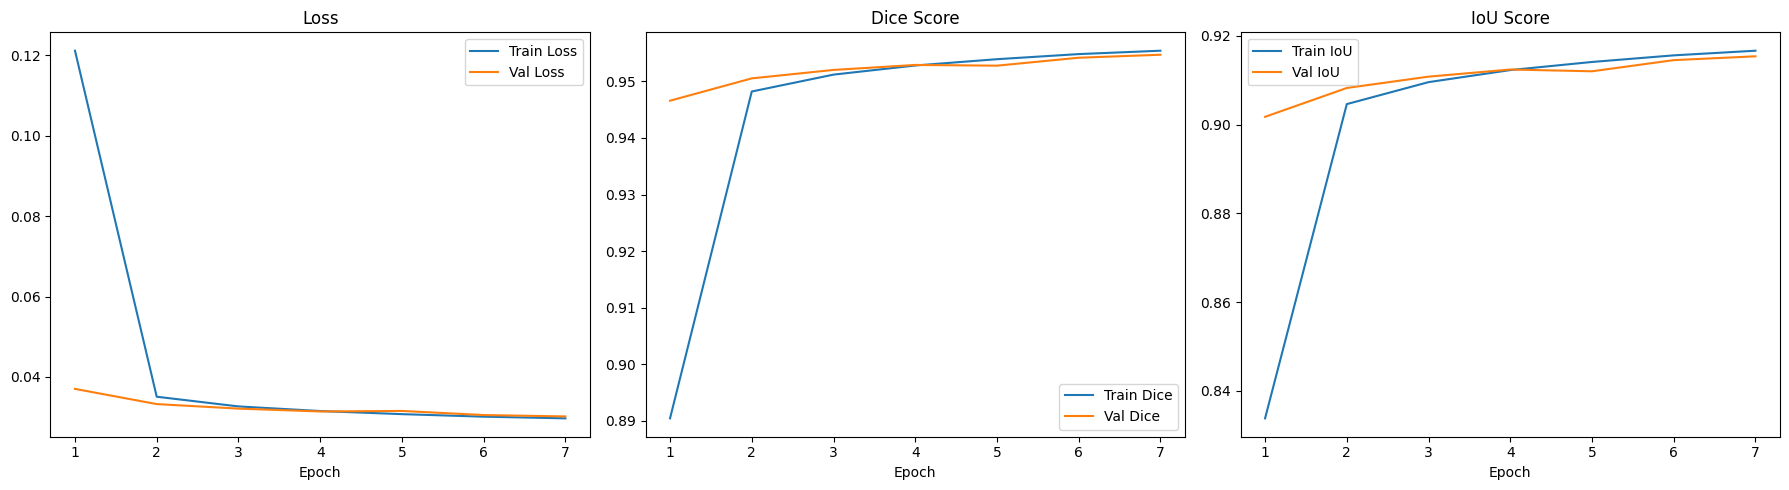

In [126]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, history["train_dice"], label="Train Dice")
axes[1].plot(epochs_range, history["val_dice"], label="Val Dice")
axes[1].set_title("Dice Score")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(epochs_range, history["train_iou"], label="Train IoU")
axes[2].plot(epochs_range, history["val_iou"], label="Val IoU")
axes[2].set_title("IoU Score")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()


### Cell 38: Prediction visualization
Show input image, ground-truth mask, predicted mask, and a red overlay of the prediction for a few test samples.

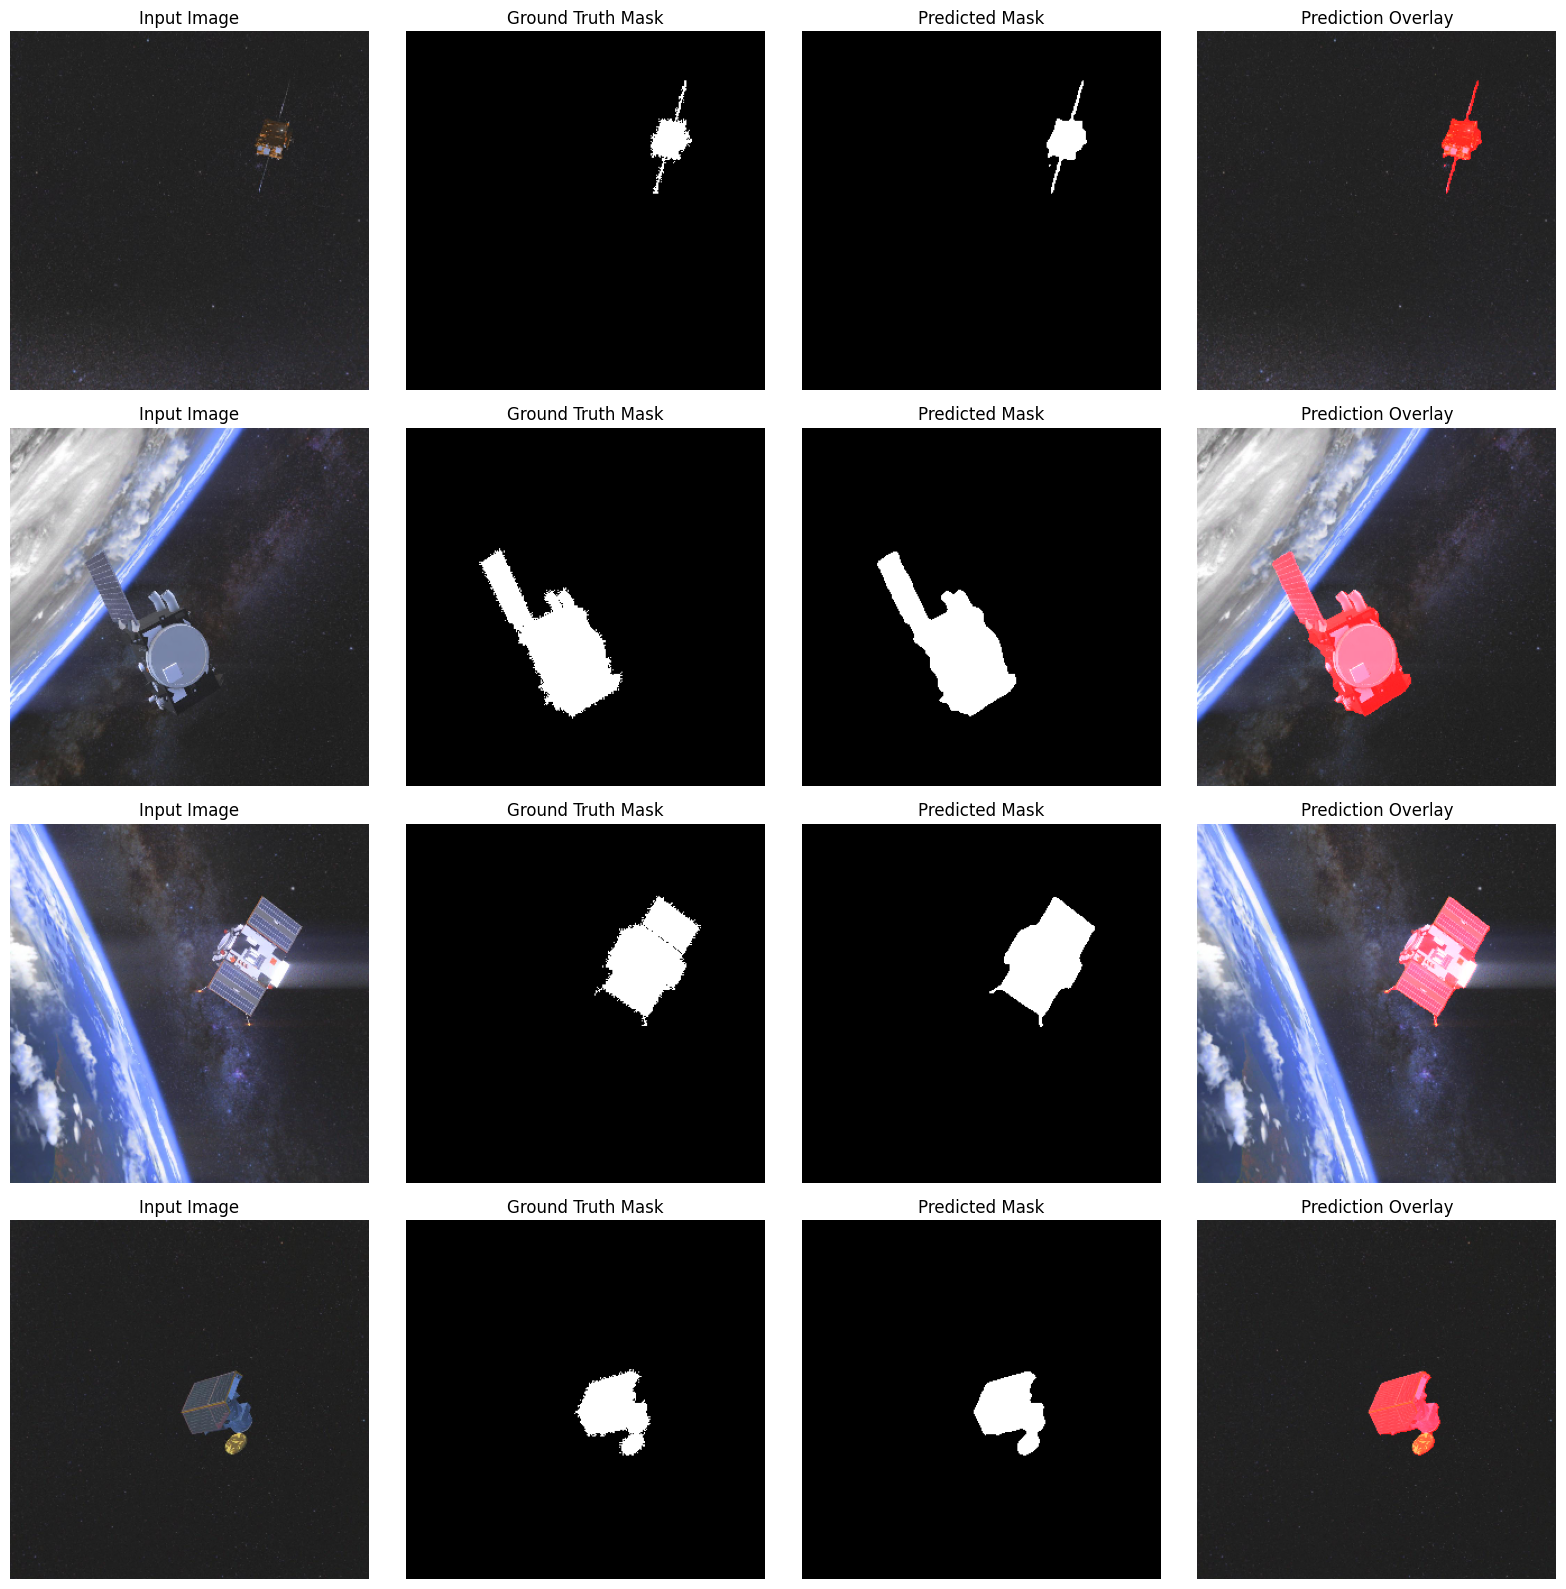

In [127]:
def denormalize_image(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

model.eval()
n_show = 4

images, masks, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    seg_logits, _ = model(images)
    preds = (torch.sigmoid(seg_logits) > 0.5).float().squeeze(1)

n_show = min(n_show, images.shape[0])

fig, axes = plt.subplots(n_show, 4, figsize=(16, 4 * n_show))

for i in range(n_show):
    img = denormalize_image(images[i])
    gt_mask = masks[i].numpy()
    pred_mask = preds[i].cpu().numpy()

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis("off")

    overlay = img.copy()
    overlay[..., 0] = np.where(pred_mask > 0.5, 1.0, overlay[..., 0])
    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Prediction Overlay")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()
